# Exercise 54 – Learning the energy of atomic clusters

**Week 10 · Training neural networks**

The dataset contains 1000 two-dimensional clusters of 12 atoms. Each cluster
has three different energy labels, computed with three unknown models. We
assume the energy is a sum of pair interactions,
$E = \sum_{i<j} V(r_{ij})$, and learn $V(r)$ in two ways:

* a **Lennard-Jones-Gauss** potential with five trainable constants
  (we know the functional form), and
* a **neural network** $V(r)$ (we do not).

Comparing the two tells us which labels really come from a pair potential of
LJG form.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import torch
from torch.utils.data import DataLoader, TensorDataset

from comphy import DATA_DIR
from comphy.clusters import plot_cluster
from comphy.plotting import parity_plot, setup_axes
from comphy.potentials import LennardJonesGauss, NeuralPairPotential
from comphy.training import evaluate, predict, train

torch.manual_seed(0)

raw = np.loadtxt(DATA_DIR / "pos_e1_e2_e3_1000.txt")
positions = torch.tensor(raw[:, :24].reshape(-1, 12, 2), dtype=torch.float32)
energies = torch.tensor(raw[:, 24:27], dtype=torch.float32)       # (1000, 3)
print(positions.shape, energies.shape)

torch.Size([1000, 12, 2]) torch.Size([1000, 3])


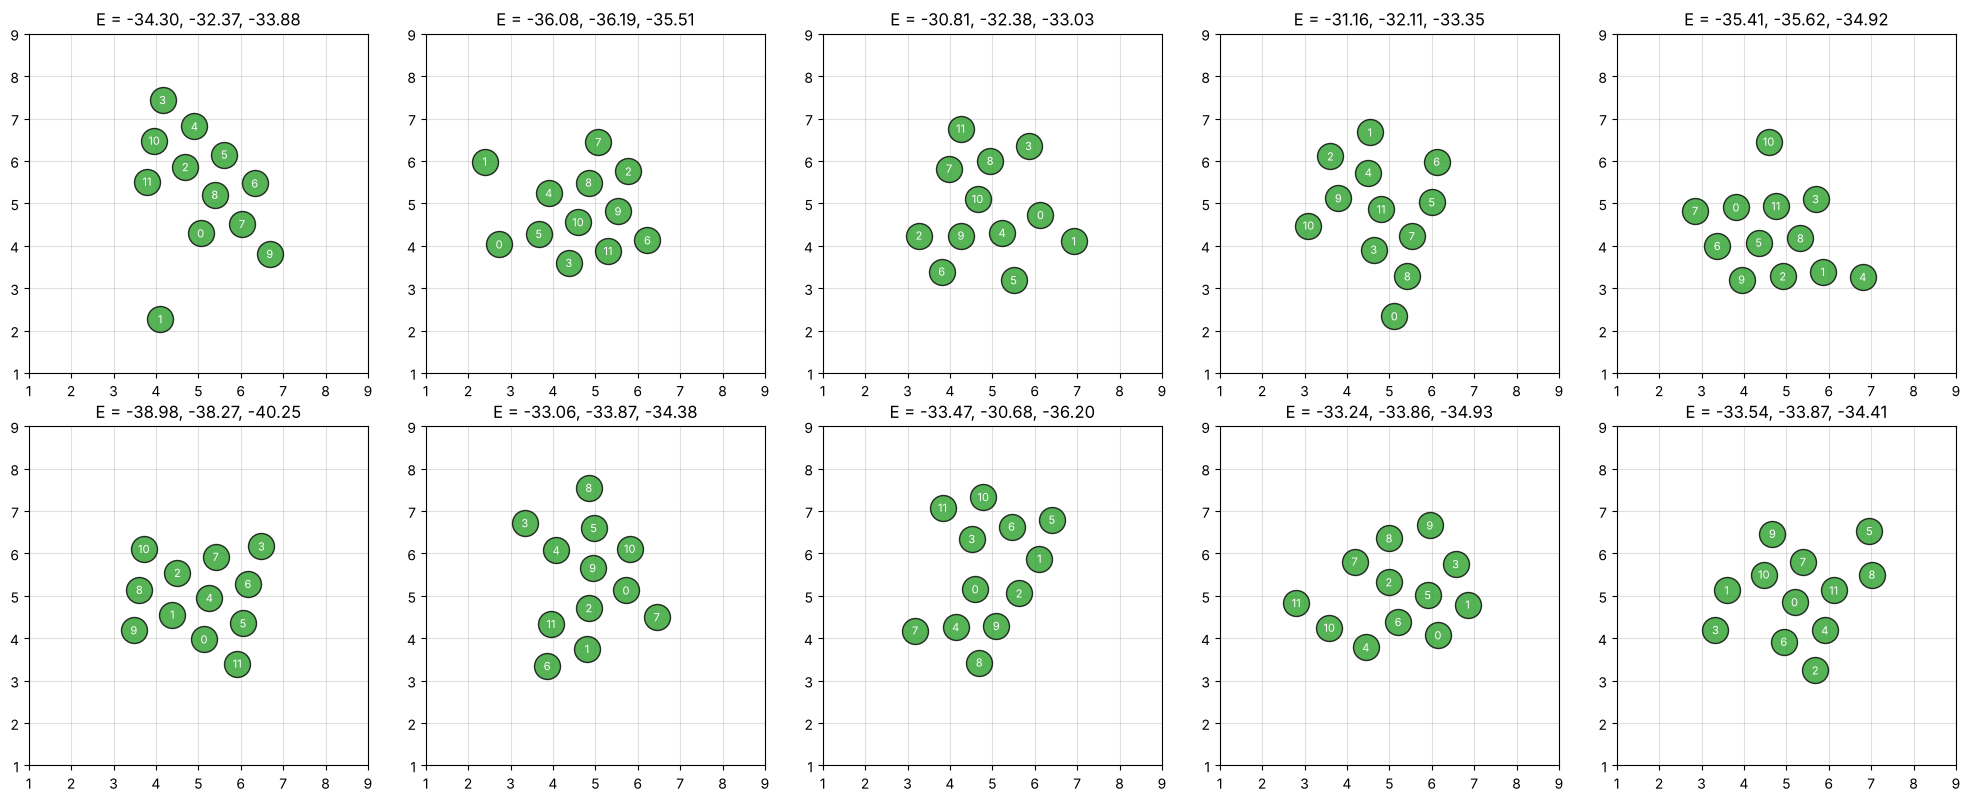

In [2]:
fig, axes = plt.subplots(2, 5, figsize=(20, 8))
for ax, pos, e in zip(axes.flat, positions, energies):
    plot_cluster(ax, pos, color="C2", size=350, alpha=0.8)
    setup_axes(ax, xlim=(1, 9), ylim=(1, 9), zero_lines=False, xlabel=None, ylabel=None,
               title=f"E = {e[0]:.2f}, {e[1]:.2f}, {e[2]:.2f}")
fig.tight_layout()
plt.show()

How do the three labels compare?

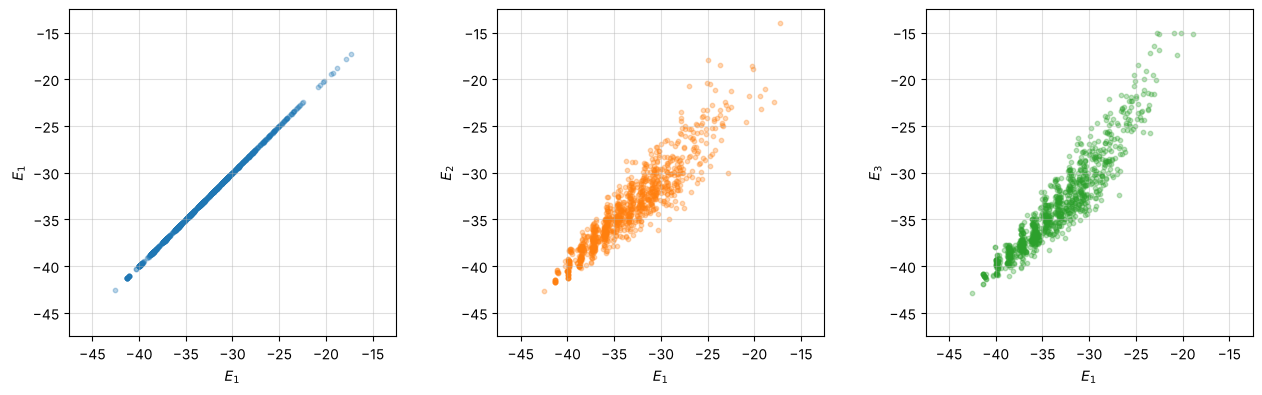

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for k, ax in enumerate(axes):
    ax.scatter(energies[:, 0], energies[:, k], color=f"C{k}", alpha=0.3, s=10)
    ax.set(xlim=(-47.5, -12.5), ylim=(-47.5, -12.5), xlabel="$E_1$", ylabel=f"$E_{k + 1}$",
           aspect="equal")
    ax.grid(True, alpha=0.4)
fig.tight_layout()
plt.show()

## Training both models for each energy label

80 % / 10 % / 10 % split into training, validation and test sets.

In [4]:
n_train, n_val = 800, 100


def loaders(label):
    y = energies[:, label]
    sets = [TensorDataset(positions[s], y[s]) for s in
            (slice(0, n_train), slice(n_train, n_train + n_val), slice(n_train + n_val, None))]
    return (DataLoader(sets[0], batch_size=128, shuffle=True),
            DataLoader(sets[1], batch_size=128), DataLoader(sets[2], batch_size=128))


results = {}
for label in range(3):
    train_loader, val_loader, test_loader = loaders(label)
    print(f"--- energy label {label + 1} ---")
    torch.manual_seed(0)
    ljg = LennardJonesGauss(eps=0.5, sigma_squared=0.03, r0=1.6, A=0.9, e_inf=0.1, trainable=True)
    h_ljg = train(ljg, train_loader, val_loader, epochs=3000, lr=0.01, patience=50,
                  restore_best=True)
    torch.manual_seed(0)
    nn_pot = NeuralPairPotential(hidden=(8, 8, 8))
    h_nn = train(nn_pot, train_loader, val_loader, epochs=5000, lr=0.01, patience=300,
                 restore_best=True)
    results[label] = dict(loaders=(train_loader, val_loader, test_loader),
                          models={"LJG": ljg, "NN": nn_pot}, history={"LJG": h_ljg, "NN": h_nn},
                          test={"LJG": evaluate(ljg, test_loader), "NN": evaluate(nn_pot, test_loader)})
    print(f"test MSE   LJG: {results[label]['test']['LJG']:.4g}   NN: {results[label]['test']['NN']:.4g}")
    print(f"fitted LJG: {ljg.extra_repr()}")

--- energy label 1 ---


Early stopping at epoch 792


Early stopping at epoch 917
test MSE   LJG: 1.732e-11   NN: 0.3238
fitted LJG: eps=0.000, sigma_squared=0.190, r0=1.598, A=1.300, e_inf=-0.152
--- energy label 2 ---


Early stopping at epoch 622


Early stopping at epoch 2351
test MSE   LJG: 8.253e-07   NN: 0.4505
fitted LJG: eps=0.999, sigma_squared=0.020, r0=1.700, A=1.000, e_inf=-0.000
--- energy label 3 ---


Early stopping at epoch 980


Early stopping at epoch 1064
test MSE   LJG: 2.702   NN: 2.289
fitted LJG: eps=0.251, sigma_squared=0.580, r0=2.626, A=1.454, e_inf=0.075


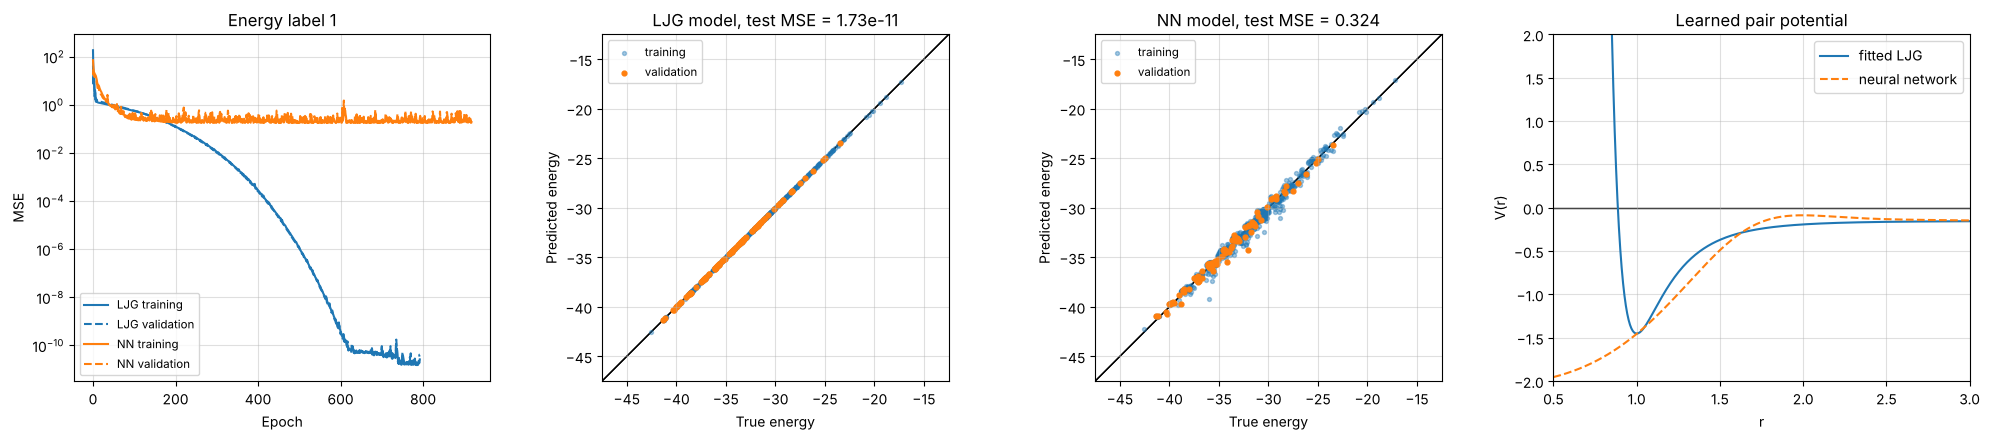

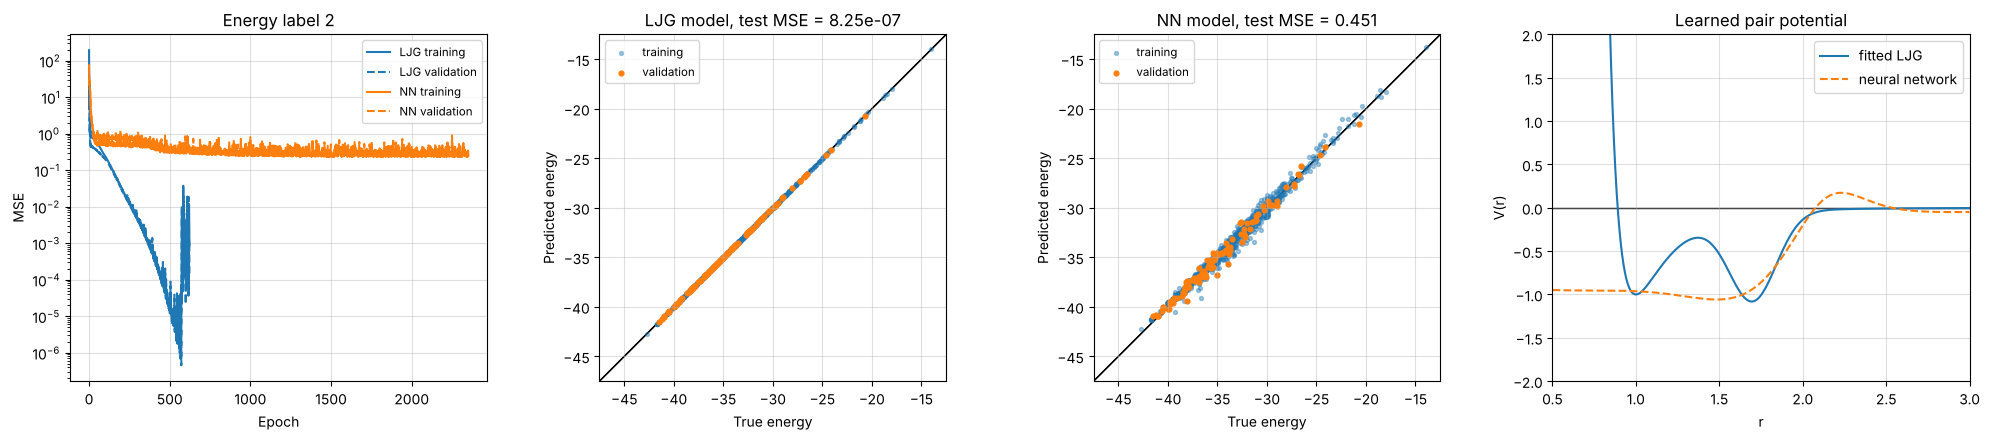

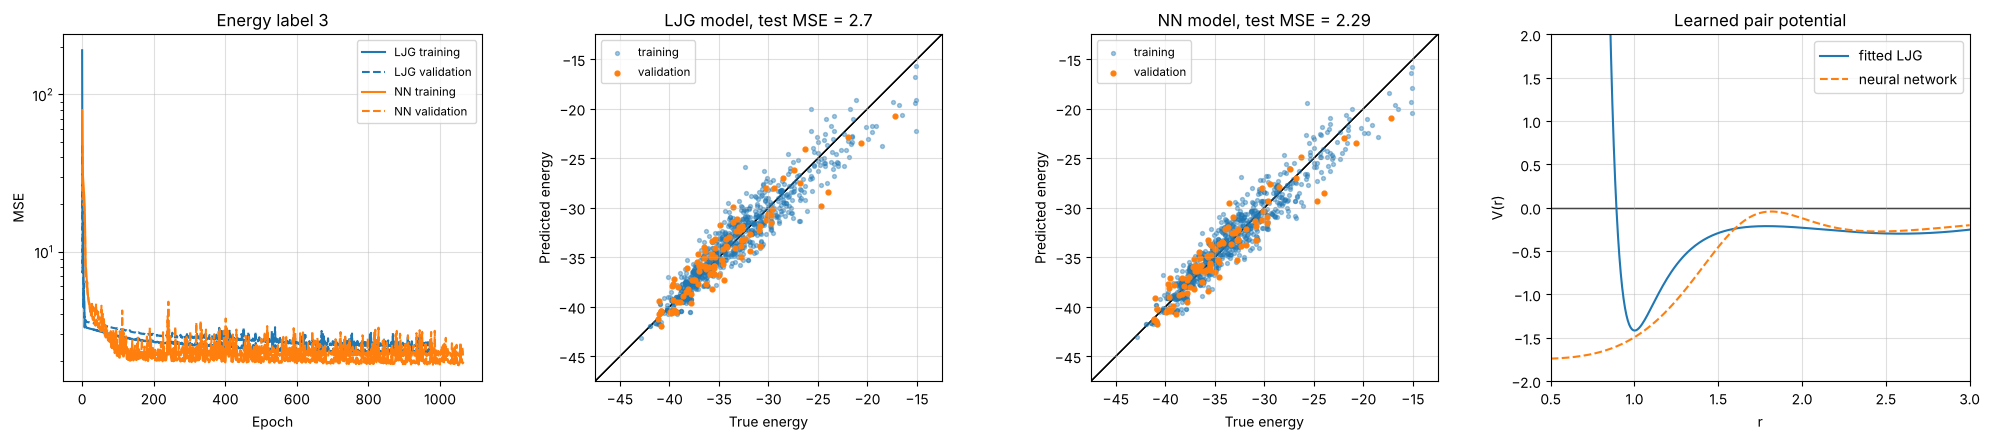

In [5]:
rs = torch.linspace(0.5, 3.0, 300)
lims = (-47.5, -12.5)
for label, res in results.items():
    fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
    for i, name in enumerate(["LJG", "NN"]):
        h = res["history"][name]
        axes[0].plot(h["train"], color=f"C{i}", label=f"{name} training")
        axes[0].plot(h["val"], color=f"C{i}", ls="--", label=f"{name} validation")
    axes[0].set(yscale="log", xlabel="Epoch", ylabel="MSE", title=f"Energy label {label + 1}")
    axes[0].legend(fontsize="small")
    axes[0].grid(True, alpha=0.4)
    train_loader, val_loader, test_loader = res["loaders"]
    for ax, name in zip(axes[1:3], ["LJG", "NN"]):
        model = res["models"][name]
        parity_plot(ax, *predict(model, train_loader), label="training", lims=lims, s=8, alpha=0.4)
        parity_plot(ax, *predict(model, val_loader), label="validation", lims=lims, s=12)
        ax.set_title(f"{name} model, test MSE = {res['test'][name]:.3g}")
        ax.legend(loc="upper left", fontsize="small")
    with torch.no_grad():
        axes[3].plot(rs, res["models"]["LJG"].V(rs), label="fitted LJG")
        axes[3].plot(rs, res["models"]["NN"].V(rs), "--", label="neural network")
    setup_axes(axes[3], xlim=(0.5, 3), ylim=(-2, 2), xlabel="r", ylabel="V(r)",
               title="Learned pair potential")
    axes[3].legend()
    fig.tight_layout()
    plt.show()

## What the fits tell us

* **Label 1** is reproduced essentially exactly by the LJG form, but with
  $\varepsilon \to 0$: these energies come from a pure (scaled) Lennard-Jones
  potential.
* **Label 2** is reproduced exactly with $\varepsilon = 1$, $\sigma^2 = 0.02$,
  $r_0 = 1.7$, $A = 1$, $E_\infty = 0$ – the Lennard-Jones-Gauss potential used
  in exercise 47.
* **Label 3** cannot be described by either model (test errors of order 1),
  so it is not a sum of pair interactions of this kind.

The neural network pair potential is more flexible but harder to train: with
this small network it gives decent energies but a much less accurate $V(r)$,
especially at short distances where there are few training pairs. Knowing
the right functional form is a big advantage.